# Budget-Based Shopping Optimizer Using 0/1 Knapsack Algorithm

## 1. Introduction
The Budget-Based Shopping Optimizer is a mini-project based on Design and Analysis of Algorithms (DAA). It helps users select suitable products within a limited budget while maximizing the total value of their purchases.

## 2. Problem Statement
When shopping with a limited budget, it can be difficult to decide which products provide the best overall value. This project uses the 0/1 Knapsack algorithm to find an optimal combination of items without exceeding the available budget.

## 3. Objectives
- To implement the 0/1 Knapsack algorithm using Dynamic Programming.
- To select products within a given budget.
- To maximize the total value of selected products.
- To calculate total spending and the remaining budget.
- To analyze the time and space complexity of the algorithm.

## 4. Software and Tools
- Python programming language
- Google Colab
- Matplotlib for graphical visualization

## 5. Expected Outcome
The system will display the selected products, their total price, the remaining budget, and the maximum achievable total value.

In [2]:

# DAA Mini Project
# Budget-Based Shopping Optimizer

items = [
    {"name": "Shoes", "price": 500, "value": 80},
    {"name": "Bag", "price": 300, "value": 50},
    {"name": "Headphones", "price": 400, "value": 70},
    {"name": "Book", "price": 200, "value": 40},
    {"name": "Bottle", "price": 100, "value": 20}
]

budget = 1000

print("BUDGET-BASED SHOPPING OPTIMIZER")
print("--------------------------------")
print("Available Budget: Rs.", budget)

print("\nAvailable Products:")
for item in items:
    print(
        item["name"],
        "- Price: Rs.", item["price"],
        "- Value:", item["value"]
    )


BUDGET-BASED SHOPPING OPTIMIZER
--------------------------------
Available Budget: Rs. 1000

Available Products:
Shoes - Price: Rs. 500 - Value: 80
Bag - Price: Rs. 300 - Value: 50
Headphones - Price: Rs. 400 - Value: 70
Book - Price: Rs. 200 - Value: 40
Bottle - Price: Rs. 100 - Value: 20


In [3]:

# Step 3: 0/1 Knapsack using Dynamic Programming

n = len(items)

# Create the DP table
dp = [
    [0] * (budget + 1)
    for _ in range(n + 1)
]

# Fill the DP table
for i in range(1, n + 1):
    price = items[i - 1]["price"]
    value = items[i - 1]["value"]

    for b in range(budget + 1):
        # Option 1: Do not select the item
        dp[i][b] = dp[i - 1][b]

        # Option 2: Select the item if it fits
        if price <= b:
            dp[i][b] = max(
                dp[i][b],
                value + dp[i - 1][b - price]
            )

# Recover the selected products
selected_items = []
remaining_budget = budget

for i in range(n, 0, -1):
    if dp[i][remaining_budget] != dp[i - 1][remaining_budget]:
        selected_items.append(items[i - 1])
        remaining_budget -= items[i - 1]["price"]

# Calculate final results
total_price = sum(
    item["price"] for item in selected_items
)
total_value = sum(
    item["value"] for item in selected_items
)

# Display the result
print("===== OPTIMIZED SHOPPING RESULT =====")
print("Available Budget: Rs.", budget)
print("\nSelected Products:")

for item in selected_items:
    print(
        item["name"],
        "- Price: Rs.", item["price"],
        "- Value:", item["value"]
    )

print("\nTotal Spending: Rs.", total_price)
print("Remaining Budget: Rs.", budget - total_price)
print("Maximum Total Value:", total_value)


===== OPTIMIZED SHOPPING RESULT =====
Available Budget: Rs. 1000

Selected Products:
Bottle - Price: Rs. 100 - Value: 20
Book - Price: Rs. 200 - Value: 40
Headphones - Price: Rs. 400 - Value: 70
Bag - Price: Rs. 300 - Value: 50

Total Spending: Rs. 1000
Remaining Budget: Rs. 0
Maximum Total Value: 180


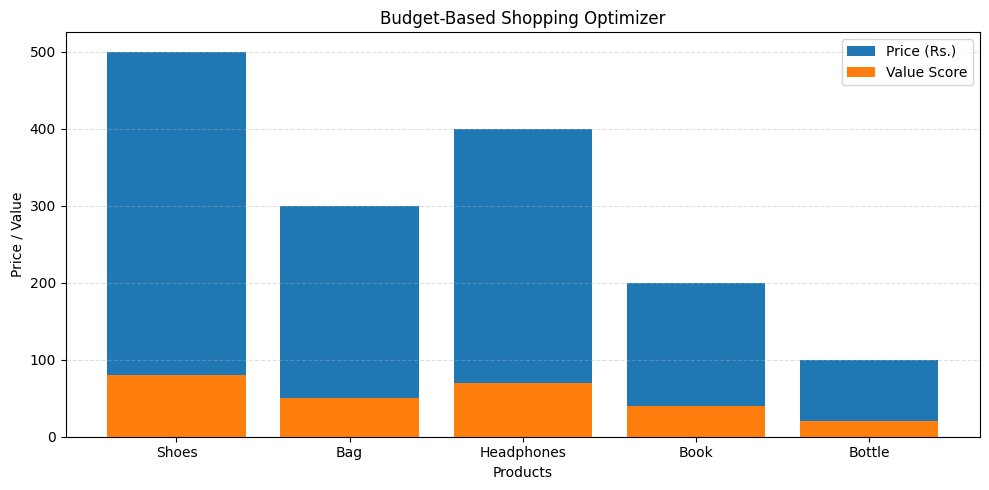

In [4]:

# Step 4: Product Price and Value Visualization

import matplotlib.pyplot as plt

# Extract product names, prices, and values
names = [item["name"] for item in items]
prices = [item["price"] for item in items]
values = [item["value"] for item in items]

# Create the bar chart
plt.figure(figsize=(10, 5))

plt.bar(names, prices, label="Price (Rs.)")
plt.bar(names, values, label="Value Score")

plt.title("Budget-Based Shopping Optimizer")
plt.xlabel("Products")
plt.ylabel("Price / Value")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


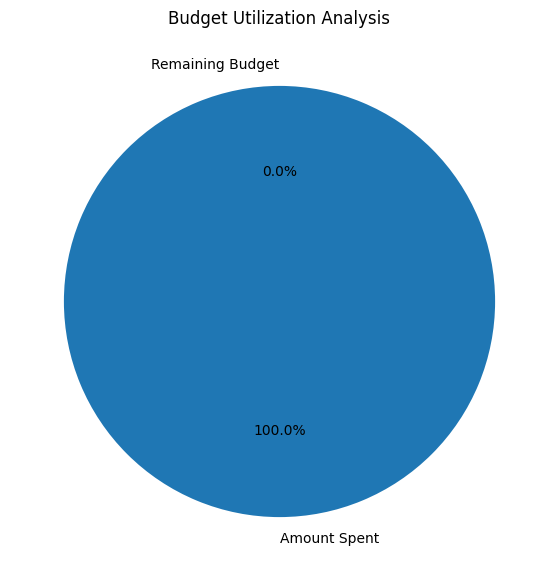

BUDGET UTILIZATION REPORT
-------------------------
Total Budget: Rs. 1000
Amount Spent: Rs. 1000
Remaining Budget: Rs. 0
Budget Used: 100.0 %


In [5]:

# Step 5: Budget Utilization Chart

import matplotlib.pyplot as plt

# Calculate spending and remaining budget
total_spending = sum(item["price"] for item in selected_items)
remaining = budget - total_spending

# Prepare chart data
labels = ["Amount Spent", "Remaining Budget"]
values = [total_spending, remaining]

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    values,
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Budget Utilization Analysis")
plt.show()

# Display summary
print("BUDGET UTILIZATION REPORT")
print("-------------------------")
print("Total Budget: Rs.", budget)
print("Amount Spent: Rs.", total_spending)
print("Remaining Budget: Rs.", remaining)

if budget > 0:
    print("Budget Used:", round(total_spending / budget * 100, 2), "%")


In [7]:

# Step 6: User Input for Shopping Optimizer

print("===== CUSTOM SHOPPING OPTIMIZER =====")

budget = int(input("Enter your shopping budget (Rs.): "))
n = int(input("Enter number of products: "))

items = []

for i in range(n):
    print("\nProduct", i + 1)

    name = input("Enter product name: ")
    price = int(input("Enter product price (Rs.): "))
    value = int(input("Enter product value score: "))

    items.append({
        "name": name,
        "price": price,
        "value": value
    })

# Validate inputs
if budget < 0 or n <= 0:
    print("Invalid budget or number of products.")

elif any(item["price"] <= 0 or item["value"] < 0 for item in items):
    print("Invalid input: prices must be positive and values non-negative.")

else:
    # Dynamic Programming: 0/1 Knapsack
    dp = [[0] * (budget + 1) for _ in range(n + 1)]

    for i in range(1, n + 1):
        price = items[i - 1]["price"]
        value = items[i - 1]["value"]

        for b in range(budget + 1):
            dp[i][b] = dp[i - 1][b]

            if price <= b:
                dp[i][b] = max(
                    dp[i][b],
                    value + dp[i - 1][b - price]
                )

    # Recover selected products
    selected_items = []
    remaining_budget = budget

    for i in range(n, 0, -1):
        if dp[i][remaining_budget] != dp[i - 1][remaining_budget]:
            selected_items.append(items[i - 1])
            remaining_budget -= items[i - 1]["price"]

    selected_items.reverse()

    total_spending = sum(item["price"] for item in selected_items)
    total_value = sum(item["value"] for item in selected_items)

    print("\n===== OPTIMIZED SHOPPING RESULT =====")
    print("Available Budget: Rs.", budget)
    print("\nSelected Products:")

    if selected_items:
        for item in selected_items:
            print(
                item["name"],
                "- Price: Rs.", item["price"],
                "- Value:", item["value"]
            )
    else:
        print("No products selected.")

    print("\nTotal Spending: Rs.", total_spending)
    print("Remaining Budget: Rs.", budget - total_spending)
    print("Maximum Total Value:", total_value)


===== CUSTOM SHOPPING OPTIMIZER =====


KeyboardInterrupt: Interrupted by user

In [8]:

# Step 7: Compare Greedy and Dynamic Programming

# Sample shopping data
items = [
    {"name": "Shoes", "price": 500, "value": 80},
    {"name": "Bag", "price": 300, "value": 50},
    {"name": "Headphones", "price": 400, "value": 70},
    {"name": "Book", "price": 200, "value": 40},
    {"name": "Bottle", "price": 100, "value": 20}
]

budget = 1000

# Greedy Algorithm: choose highest value-to-price ratio first
greedy_items = []
remaining = budget

sorted_items = sorted(
    items,
    key=lambda item: item["value"] / item["price"],
    reverse=True
)

for item in sorted_items:
    if item["price"] <= remaining:
        greedy_items.append(item)
        remaining -= item["price"]

greedy_value = sum(item["value"] for item in greedy_items)
greedy_cost = sum(item["price"] for item in greedy_items)

# Dynamic Programming: 0/1 Knapsack
n = len(items)
dp = [[0] * (budget + 1) for _ in range(n + 1)]

for i in range(1, n + 1):
    price = items[i - 1]["price"]
    value = items[i - 1]["value"]

    for b in range(budget + 1):
        dp[i][b] = dp[i - 1][b]

        if price <= b:
            dp[i][b] = max(
                dp[i][b],
                value + dp[i - 1][b - price]
            )

dp_items = []
remaining = budget

for i in range(n, 0, -1):
    if dp[i][remaining] != dp[i - 1][remaining]:
        dp_items.append(items[i - 1])
        remaining -= items[i - 1]["price"]

dp_value = sum(item["value"] for item in dp_items)
dp_cost = sum(item["price"] for item in dp_items)

# Display comparison
print("===== ALGORITHM COMPARISON =====")
print("\nGreedy Algorithm:")
print("Selected:", [item["name"] for item in greedy_items])
print("Total Cost: Rs.", greedy_cost)
print("Total Value:", greedy_value)

print("\nDynamic Programming:")
print("Selected:", [item["name"] for item in dp_items])
print("Total Cost: Rs.", dp_cost)
print("Total Value:", dp_value)

print("\n===== CONCLUSION =====")
if dp_value > greedy_value:
    print("Dynamic Programming gives a higher total value.")
elif dp_value == greedy_value:
    print("Both approaches give the same total value.")
else:
    print("Greedy gives a higher value for this test.")


===== ALGORITHM COMPARISON =====

Greedy Algorithm:
Selected: ['Book', 'Bottle', 'Headphones', 'Bag']
Total Cost: Rs. 1000
Total Value: 180

Dynamic Programming:
Selected: ['Bottle', 'Book', 'Headphones', 'Bag']
Total Cost: Rs. 1000
Total Value: 180

===== CONCLUSION =====
Both approaches give the same total value.


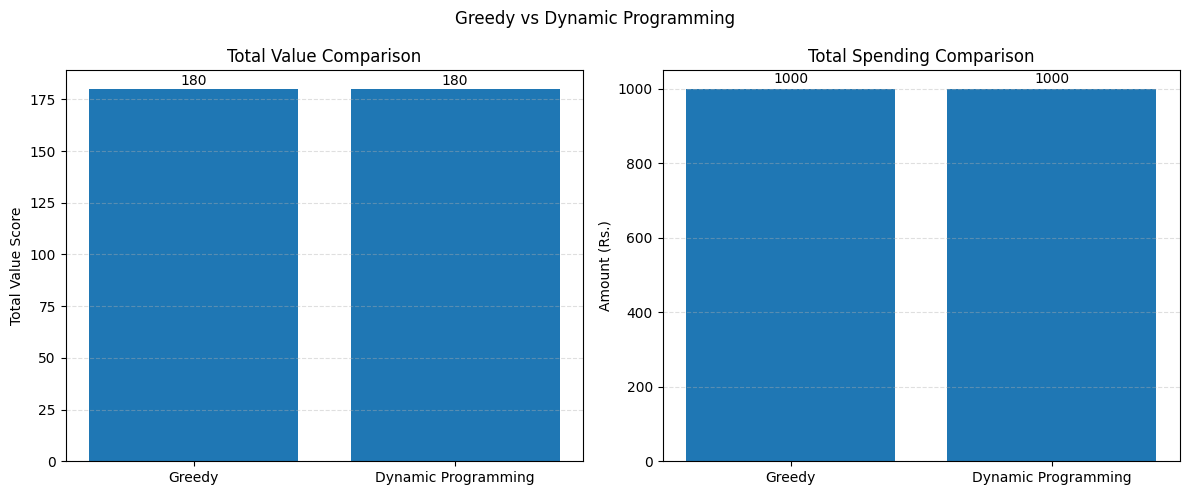

Greedy Total Value: 180
Dynamic Programming Total Value: 180
Greedy Total Cost: Rs. 1000
Dynamic Programming Total Cost: Rs. 1000


In [9]:

# Step 8: Visual Comparison of Algorithms

import matplotlib.pyplot as plt

# Results from Step 7
algorithms = ["Greedy", "Dynamic Programming"]
total_values = [greedy_value, dp_value]
total_costs = [greedy_cost, dp_cost]

# Create two comparison charts
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Compare total values
axes[0].bar(algorithms, total_values)
axes[0].set_title("Total Value Comparison")
axes[0].set_ylabel("Total Value Score")
axes[0].grid(axis="y", linestyle="--", alpha=0.4)

for i, value in enumerate(total_values):
    axes[0].text(i, value + 2, str(value), ha="center")

# Compare total spending
axes[1].bar(algorithms, total_costs)
axes[1].set_title("Total Spending Comparison")
axes[1].set_ylabel("Amount (Rs.)")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

for i, cost in enumerate(total_costs):
    axes[1].text(i, cost + 15, str(cost), ha="center")

plt.suptitle("Greedy vs Dynamic Programming")
plt.tight_layout()
plt.show()

print("Greedy Total Value:", greedy_value)
print("Dynamic Programming Total Value:", dp_value)
print("Greedy Total Cost: Rs.", greedy_cost)
print("Dynamic Programming Total Cost: Rs.", dp_cost)



In [10]:

# Step 9: Test Case for Greedy vs Dynamic Programming

test_items = [
    {"name": "Product A", "price": 10, "value": 60},
    {"name": "Product B", "price": 20, "value": 100},
    {"name": "Product C", "price": 30, "value": 120}
]

test_budget = 50

# Greedy approach
greedy_sorted = sorted(
    test_items,
    key=lambda x: x["value"] / x["price"],
    reverse=True
)

greedy_selected = []
remaining = test_budget

for item in greedy_sorted:
    if item["price"] <= remaining:
        greedy_selected.append(item)
        remaining -= item["price"]

greedy_result = sum(x["value"] for x in greedy_selected)

# Dynamic Programming approach
n = len(test_items)
dp_test = [[0] * (test_budget + 1) for _ in range(n + 1)]

for i in range(1, n + 1):
    price = test_items[i-1]["price"]
    value = test_items[i-1]["value"]

    for b in range(test_budget + 1):
        dp_test[i][b] = dp_test[i-1][b]

        if price <= b:
            dp_test[i][b] = max(
                dp_test[i][b],
                value + dp_test[i-1][b-price]
            )

dp_selected = []
remaining = test_budget

for i in range(n, 0, -1):
    if dp_test[i][remaining] != dp_test[i-1][remaining]:
        dp_selected.append(test_items[i-1])
        remaining -= test_items[i-1]["price"]

dp_result = sum(x["value"] for x in dp_selected)

print("GREEDY VS DYNAMIC PROGRAMMING")
print("--------------------------------")
print("Budget: Rs.", test_budget)

print("\nGreedy Selected:",
      [x["name"] for x in greedy_selected])
print("Greedy Total Value:", greedy_result)

print("\nDP Selected:",
      [x["name"] for x in dp_selected])
print("DP Total Value:", dp_result)


GREEDY VS DYNAMIC PROGRAMMING
--------------------------------
Budget: Rs. 50

Greedy Selected: ['Product A', 'Product B']
Greedy Total Value: 160

DP Selected: ['Product C', 'Product B']
DP Total Value: 220


PERFORMANCE ANALYSIS
--------------------
Products: 10, Time: 0.002769 seconds
Products: 20, Time: 0.009806 seconds
Products: 30, Time: 0.008238 seconds
Products: 40, Time: 0.010590 seconds
Products: 50, Time: 0.013238 seconds


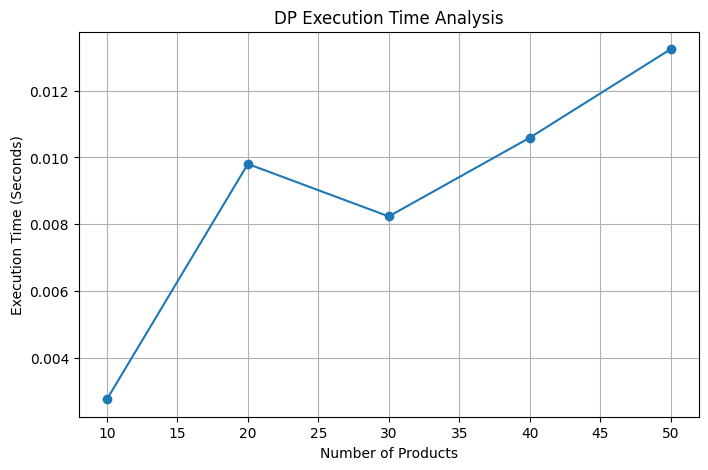

In [11]:

# Step 10: Performance Analysis

import time
import random
import matplotlib.pyplot as plt

product_counts = [10, 20, 30, 40, 50]
execution_times = []

for count in product_counts:

    test_data = [
        {
            "price": random.randint(1, 100),
            "value": random.randint(1, 100)
        }
        for _ in range(count)
    ]

    test_budget = 500

    start = time.perf_counter()

    dp = [[0] * (test_budget + 1)
          for _ in range(count + 1)]

    for i in range(1, count + 1):
        price = test_data[i-1]["price"]
        value = test_data[i-1]["value"]

        for b in range(test_budget + 1):
            dp[i][b] = dp[i-1][b]

            if price <= b:
                dp[i][b] = max(
                    dp[i][b],
                    value + dp[i-1][b-price]
                )

    end = time.perf_counter()

    execution_times.append(end - start)

print("PERFORMANCE ANALYSIS")
print("--------------------")

for count, duration in zip(product_counts, execution_times):
    print(f"Products: {count}, Time: {duration:.6f} seconds")

plt.figure(figsize=(8, 5))
plt.plot(product_counts, execution_times, marker="o")
plt.title("DP Execution Time Analysis")
plt.xlabel("Number of Products")
plt.ylabel("Execution Time (Seconds)")
plt.grid(True)
plt.show()


In [12]:
import pandas as pd

results = []

for item in selected_items:
    results.append({
        "Product Name": item["name"],
        "Price (Rs.)": item["price"],
        "Value Score": item["value"],
        "Status": "Selected"
    })

df = pd.DataFrame(results)

display(df)

df.to_csv("Shopping_Optimizer_Results.csv", index=False)

print("CSV file created successfully!")

,Product Name,Price (Rs.),Value Score,Status
0,Bottle,100,20,Selected
1,Book,200,40,Selected
2,Headphones,400,70,Selected
3,Bag,300,50,Selected


CSV file created successfully!


In [13]:
from google.colab import files
files.download("Shopping_Optimizer_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>